<a href="https://colab.research.google.com/github/saradadevivalina/banking77-intent-classifier/blob/main/banking77_intent_classifier.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Customer-Support Intent Classification with DistilBERT (Banking77)

**Goal:** route customer-support messages to the right intent automatically, e.g. *"I lost my card"* → `lost_or_stolen_card`.

**Dataset:** [Banking77](https://github.com/PolyAI-LDN/task-specific-datasets) (PolyAI): about 13,000 real online-banking customer queries labelled with **77 fine-grained intents**.

**Approach:**
1. Exploratory look at the data (class balance, message length)
2. **Baseline:** TF-IDF + Logistic Regression (classical ML)
3. **Deep learning:** fine-tune the Transformer **DistilBERT** (`distilbert-base-uncased`) with Hugging Face `Trainer`
4. Evaluate both on the held-out test set with **accuracy** and **macro-F1** (every intent counts equally)
5. **Error analysis:** which intents get confused, and why

> **Before running:** in Colab, go to **Runtime → Change runtime type → T4 GPU**, then **Runtime → Run all**. Fine-tuning takes about 5–10 minutes on the free GPU.

## 1. Setup

In [1]:
# Colab already includes torch, transformers, scikit-learn and pandas.
# accelerate is needed by the Hugging Face Trainer.
!pip install -q accelerate

import random
import numpy as np
import pandas as pd
import torch
import matplotlib.pyplot as plt
from collections import Counter

from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, f1_score, classification_report, confusion_matrix

SEED = 42
random.seed(SEED); np.random.seed(SEED); torch.manual_seed(SEED)

device = "cuda" if torch.cuda.is_available() else "cpu"
print("Using device:", device)
if device == "cpu":
    print("WARNING: no GPU found. Go to Runtime -> Change runtime type -> T4 GPU, then run again.")

Using device: cuda


## 2. Load the data
The official train/test CSV files are loaded straight from PolyAI's GitHub repository.

In [2]:
BASE = "https://raw.githubusercontent.com/PolyAI-LDN/task-specific-datasets/master/banking_data"
train_full = pd.read_csv(f"{BASE}/train.csv")   # columns: text, category
test_df = pd.read_csv(f"{BASE}/test.csv")
# Name the two columns explicitly: the message text and its intent label
train_full.columns = ["text", "category"]
test_df.columns = ["text", "category"]

print("Train rows:", len(train_full), "| Test rows:", len(test_df))
print("Number of intents:", train_full["category"].nunique())
train_full.sample(5, random_state=SEED)

Train rows: 10003 | Test rows: 3080
Number of intents: 77


,text,category
6883,Is it possible for me to change my PIN number?,change_pin
5836,I'm not sure why my card didn't work,declined_card_payment
8601,I don't think my top up worked,top_up_failed
2545,Can you explain why my payment was charged a fee?,card_payment_fee_charged
8697,How long does a transfer from a UK account tak...,balance_not_updated_after_bank_transfer


## 3. Exploratory data analysis

Examples per intent: min=35, median=127, max=187
Words per message: mean=11.9, 95th percentile=29, max=79


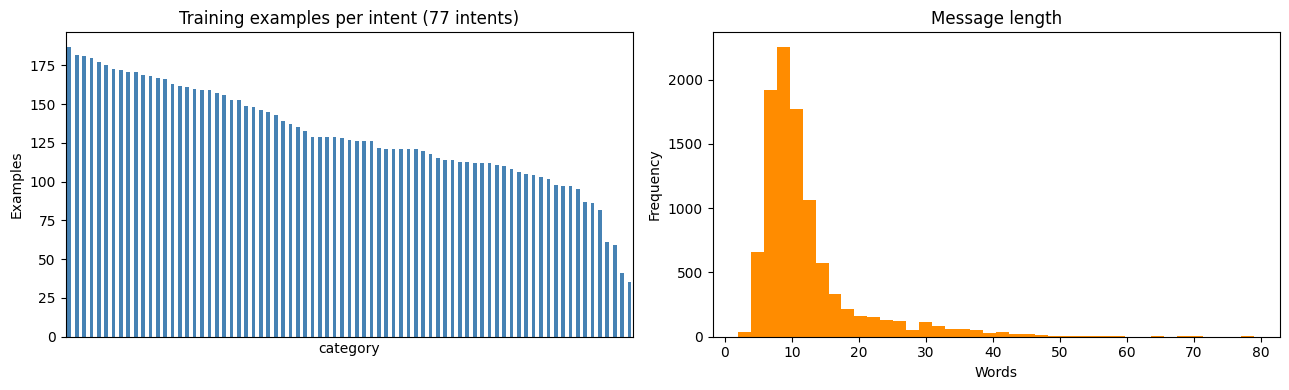

In [3]:
counts = train_full["category"].value_counts()
print(f"Examples per intent: min={counts.min()}, median={int(counts.median())}, max={counts.max()}")

lengths = train_full["text"].str.split().str.len()
print(f"Words per message: mean={lengths.mean():.1f}, 95th percentile={lengths.quantile(0.95):.0f}, max={lengths.max()}")

fig, axes = plt.subplots(1, 2, figsize=(13, 4))
counts.plot(kind="bar", ax=axes[0], color="steelblue")
axes[0].set_title("Training examples per intent (77 intents)")
axes[0].set_xticks([])
axes[0].set_ylabel("Examples")
lengths.plot(kind="hist", bins=40, ax=axes[1], color="darkorange")
axes[1].set_title("Message length")
axes[1].set_xlabel("Words")
plt.tight_layout(); plt.show()

**Reading the EDA:** the classes are *moderately* imbalanced, so **macro-F1** (the average F1 across all 77 intents) is reported alongside accuracy. That way rare intents count as much as common ones. Messages are short, so a maximum sequence length of 64 tokens is enough for the Transformer.

## 4. Encode labels and create a validation split
The official test set is kept untouched for the final comparison. A stratified 10% of the training data is held out for validation during fine-tuning.

In [4]:
labels = sorted(train_full["category"].unique())
label2id = {label: i for i, label in enumerate(labels)}
id2label = {i: label for label, i in label2id.items()}

train_full["label"] = train_full["category"].map(label2id)
test_df["label"] = test_df["category"].map(label2id)

train_df, val_df = train_test_split(
    train_full, test_size=0.10, stratify=train_full["label"], random_state=SEED
)
print("Train:", len(train_df), "| Validation:", len(val_df), "| Test:", len(test_df))

Train: 9002 | Validation: 1001 | Test: 3080


## 5. Baseline: TF-IDF + Logistic Regression
A strong classical baseline. The Transformer has to beat this for the extra complexity to be worth it.

In [5]:
tfidf = TfidfVectorizer(ngram_range=(1, 2), min_df=2, sublinear_tf=True)
X_train = tfidf.fit_transform(train_df["text"])   # fit on training data only (no leakage)
X_test = tfidf.transform(test_df["text"])

baseline = LogisticRegression(max_iter=2000, C=10)
baseline.fit(X_train, train_df["label"])
baseline_pred = baseline.predict(X_test)

baseline_acc = accuracy_score(test_df["label"], baseline_pred)
baseline_f1 = f1_score(test_df["label"], baseline_pred, average="macro")
print(f"Baseline TF-IDF + LogReg  ->  accuracy: {baseline_acc:.4f} | macro-F1: {baseline_f1:.4f}")

Baseline TF-IDF + LogReg  ->  accuracy: 0.8851 | macro-F1: 0.8854


## 6. Fine-tune DistilBERT
`distilbert-base-uncased` is a smaller, faster version of BERT (about 66M parameters). A classification head with 77 outputs is added on top and the whole network is fine-tuned on our data.

In [6]:
from datasets import Dataset
from transformers import (
    AutoTokenizer, AutoModelForSequenceClassification,
    DataCollatorWithPadding, TrainingArguments, Trainer,
)

MODEL_NAME = "distilbert-base-uncased"
tokenizer = AutoTokenizer.from_pretrained(MODEL_NAME)

def tokenize(batch):
    return tokenizer(batch["text"], truncation=True, max_length=64)

def to_dataset(df):
    return Dataset.from_pandas(df[["text", "label"]].reset_index(drop=True)).map(tokenize, batched=True)

train_ds, val_ds, test_ds = to_dataset(train_df), to_dataset(val_df), to_dataset(test_df)

model = AutoModelForSequenceClassification.from_pretrained(
    MODEL_NAME, num_labels=len(labels), id2label=id2label, label2id=label2id
)

def compute_metrics(eval_pred):
    logits, y_true = eval_pred
    y_pred = np.argmax(logits, axis=-1)
    return {
        "accuracy": accuracy_score(y_true, y_pred),
        "macro_f1": f1_score(y_true, y_pred, average="macro"),
    }

args = TrainingArguments(
    output_dir="distilbert-banking77",
    num_train_epochs=4,
    learning_rate=5e-5,
    per_device_train_batch_size=32,
    per_device_eval_batch_size=64,
    weight_decay=0.01,
    warmup_steps=100,                  # gentle learning-rate warm-up (~10% of training)
    eval_strategy="epoch",
    save_strategy="epoch",
    load_best_model_at_end=True,       # keep the epoch with the best validation macro-F1
    metric_for_best_model="macro_f1",
    save_total_limit=1,
    fp16=torch.cuda.is_available(),    # faster mixed-precision training on the GPU
    logging_steps=50,
    report_to="none",
    seed=SEED,
)

trainer = Trainer(
    model=model,
    args=args,
    train_dataset=train_ds,
    eval_dataset=val_ds,
    processing_class=tokenizer,
    data_collator=DataCollatorWithPadding(tokenizer),
    compute_metrics=compute_metrics,
)
trainer.train()

config.json:   0%|          | 0.00/483 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/48.0 [00:00<?, ?B/s]

vocab.txt:   0%|          | 0.00/232k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/466k [00:00<?, ?B/s]

Map:   0%|          | 0/9002 [00:00<?, ? examples/s]

...

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

TrainOutput(global_step=1128, training_loss=1.1226416141428845, metrics={'train_runtime': 102.4615, 'train_samples_per_second': 351.43, 'train_steps_per_second': 11.009, 'total_flos': 432156029442048.0, 'train_loss': 1.1226416141428845, 'epoch': 4.0})

### Training curve (validation metrics per epoch)

 epoch  eval_loss  eval_accuracy  eval_macro_f1
   1.0   1.379098       0.759241       0.698516
   2.0   0.517257       0.892108       0.884857
   3.0   0.379315       0.905095       0.909836
   4.0   0.347381       0.911089       0.915340


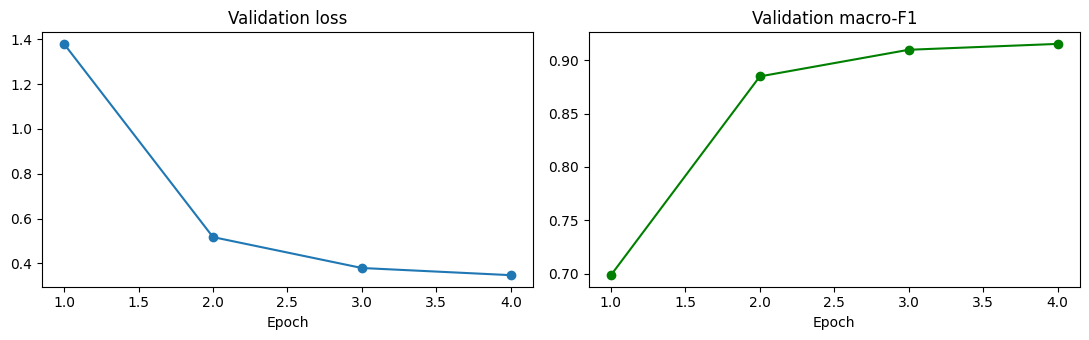

In [7]:
history = pd.DataFrame(trainer.state.log_history)
val_hist = history.dropna(subset=["eval_macro_f1"])[["epoch", "eval_loss", "eval_accuracy", "eval_macro_f1"]]
print(val_hist.to_string(index=False))

fig, ax = plt.subplots(1, 2, figsize=(11, 3.5))
ax[0].plot(val_hist["epoch"], val_hist["eval_loss"], marker="o"); ax[0].set_title("Validation loss"); ax[0].set_xlabel("Epoch")
ax[1].plot(val_hist["epoch"], val_hist["eval_macro_f1"], marker="o", color="green"); ax[1].set_title("Validation macro-F1"); ax[1].set_xlabel("Epoch")
plt.tight_layout(); plt.show()

## 7. Final evaluation on the held-out test set

In [8]:
test_output = trainer.predict(test_ds)
bert_pred = np.argmax(test_output.predictions, axis=-1)

bert_acc = accuracy_score(test_df["label"], bert_pred)
bert_f1 = f1_score(test_df["label"], bert_pred, average="macro")

results = pd.DataFrame({
    "Model": ["TF-IDF + Logistic Regression (baseline)", "DistilBERT fine-tuned"],
    "Test accuracy": [baseline_acc, bert_acc],
    "Test macro-F1": [baseline_f1, bert_f1],
}).round(4)
print(results.to_string(index=False))
print(f"\nImprovement over baseline: +{(bert_acc - baseline_acc) * 100:.1f} accuracy points, "
      f"+{(bert_f1 - baseline_f1) * 100:.1f} macro-F1 points")

                                  Model  Test accuracy  Test macro-F1
TF-IDF + Logistic Regression (baseline)         0.8851         0.8854
                  DistilBERT fine-tuned         0.9169         0.9168

Improvement over baseline: +3.2 accuracy points, +3.1 macro-F1 points


## 8. Error analysis
Which intents does the fine-tuned model find hardest, and which pairs does it confuse?

In [9]:
report = classification_report(test_df["label"], bert_pred, target_names=labels, output_dict=True, zero_division=0)
per_class = pd.DataFrame(report).T.iloc[:len(labels)][["precision", "recall", "f1-score", "support"]]
print("5 hardest intents (lowest F1):")
print(per_class.sort_values("f1-score").head(5).round(3).to_string())

cm = confusion_matrix(test_df["label"], bert_pred)
np.fill_diagonal(cm, 0)
pairs = [(cm[i, j], id2label[i], id2label[j]) for i in range(len(labels)) for j in range(len(labels)) if cm[i, j] > 0]
pairs.sort(reverse=True)
print("\nMost frequent confusions (true -> predicted):")
for n, true_label, pred_label in pairs[:8]:
    print(f"  {n:>2} x  {true_label}  ->  {pred_label}")

5 hardest intents (lowest F1):
                                         precision  recall  f1-score  support
why_verify_identity                          0.794   0.675     0.730     40.0
topping_up_by_card                           0.795   0.775     0.785     40.0
balance_not_updated_after_bank_transfer      0.816   0.775     0.795     40.0
compromised_card                             0.825   0.825     0.825     40.0
verify_my_identity                           0.745   0.950     0.835     40.0

Most frequent confusions (true -> predicted):
  12 x  why_verify_identity  ->  verify_my_identity
   5 x  balance_not_updated_after_bank_transfer  ->  transfer_timing
   4 x  unable_to_verify_identity  ->  why_verify_identity
   4 x  transfer_into_account  ->  topping_up_by_card
   4 x  get_disposable_virtual_card  ->  getting_virtual_card
   4 x  declined_transfer  ->  declined_card_payment
   3 x  wrong_amount_of_cash_received  ->  declined_cash_withdrawal
   3 x  transfer_timing  ->  balance_

In [10]:
# A few misclassified test messages, to see WHY the model got them wrong
wrong = test_df.assign(predicted=[id2label[p] for p in bert_pred])
wrong = wrong[wrong["label"] != bert_pred][["text", "category", "predicted"]]
print(f"Misclassified: {len(wrong)} of {len(test_df)} test messages")
wrong.sample(min(8, len(wrong)), random_state=SEED)

Misclassified: 256 of 3080 test messages


,text,category,predicted
2636,Can i get a throw away card,get_disposable_virtual_card,order_physical_card
173,Where did this fee come from?,extra_charge_on_statement,card_payment_fee_charged
1038,On my last transaction it seem that my top-up ...,top_up_reverted,top_up_failed
2468,how come i can't find anywhere to load using cash,top_up_by_cash_or_cheque,wrong_exchange_rate_for_cash_withdrawal
1340,Is there a way to transfer funds directly from...,topping_up_by_card,transfer_into_account
2195,Can you help with a transfer to an account,beneficiary_not_allowed,transfer_into_account
2745,I need to cancel my card that got stolen a lit...,cash_withdrawal_not_recognised,lost_or_stolen_card
1922,I was retrieving money and my card wouldn't re...,card_swallowed,topping_up_by_card


**Interpreting the errors:** most mistakes are between intents that are genuinely close in meaning (for example different kinds of card or transfer problems). Often the message itself is ambiguous even for a human agent. A production system could handle these with a confidence threshold that hands low-confidence messages to a human, or asks the customer a clarifying question.

## 9. Try the model

In [11]:
def predict_intent(message, top_k=3):
    inputs = tokenizer(message, return_tensors="pt", truncation=True, max_length=64).to(trainer.model.device)
    with torch.no_grad():
        probs = torch.softmax(trainer.model(**inputs).logits, dim=-1)[0]
    top = torch.topk(probs, top_k)
    return [(id2label[i.item()], round(p.item(), 3)) for p, i in zip(top.values, top.indices)]

for msg in [
    "I lost my card yesterday, what should I do?",
    "Why was I charged twice for the same purchase?",
    "My transfer still hasn't arrived after 3 days",
    "Can I change my PIN at an ATM?",
]:
    print(msg, "->", predict_intent(msg))

I lost my card yesterday, what should I do? -> [('lost_or_stolen_card', 0.867), ('card_arrival', 0.03), ('card_linking', 0.021)]
Why was I charged twice for the same purchase? -> [('transaction_charged_twice', 0.977), ('card_payment_wrong_exchange_rate', 0.002), ('extra_charge_on_statement', 0.002)]
My transfer still hasn't arrived after 3 days -> [('transfer_not_received_by_recipient', 0.888), ('balance_not_updated_after_bank_transfer', 0.059), ('pending_transfer', 0.021)]
Can I change my PIN at an ATM? -> [('change_pin', 0.967), ('get_physical_card', 0.005), ('pin_blocked', 0.004)]


## 10. Save the model

In [12]:
trainer.save_model("distilbert-banking77-final")
tokenizer.save_pretrained("distilbert-banking77-final")
print("Saved to ./distilbert-banking77-final")

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Saved to ./distilbert-banking77-final


## 11. Business impact: how much can be routed automatically?

A support team does not need the model to be right about *every* message. It needs to know **which messages it can safely route on its own** and which should go to a human agent. The model's softmax probability is used as a confidence score: messages above a threshold are auto-routed, the rest go to an agent.

 confidence threshold  auto-routed (%)  accuracy on auto-routed (%)  sent to an agent (%)
                  0.0            100.0                         91.7                   0.0
                  0.5             94.6                         94.6                   5.4
                  0.7             87.9                         97.0                  12.1
                  0.8             81.3                         97.9                  18.7
                  0.9             67.6                         98.8                  32.4
                  1.0             44.9                         99.6                  55.1


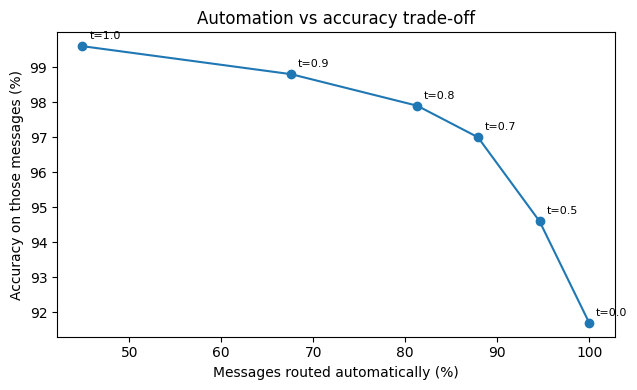


At a 0.9 confidence threshold the model auto-routes 67.6% of messages with 98.8% accuracy; 32.4% go to an agent.


In [13]:
probs = torch.softmax(torch.tensor(test_output.predictions, dtype=torch.float32), dim=-1).numpy()
confidence = probs.max(axis=1)
is_correct = bert_pred == test_df["label"].values

rows = []
for t in [0.0, 0.5, 0.7, 0.8, 0.9, 0.95]:
    auto = confidence >= t
    rows.append({
        "confidence threshold": t,
        "auto-routed (%)": 100 * auto.mean(),
        "accuracy on auto-routed (%)": 100 * is_correct[auto].mean() if auto.any() else float("nan"),
        "sent to an agent (%)": 100 * (1 - auto.mean()),
    })
threshold_table = pd.DataFrame(rows).round(1)
print(threshold_table.to_string(index=False))

fig, ax = plt.subplots(figsize=(6.5, 4))
ax.plot(threshold_table["auto-routed (%)"], threshold_table["accuracy on auto-routed (%)"], marker="o")
for _, row in threshold_table.iterrows():
    ax.annotate(f"t={row['confidence threshold']}", (row["auto-routed (%)"], row["accuracy on auto-routed (%)"]),
                textcoords="offset points", xytext=(5, 5), fontsize=8)
ax.set_xlabel("Messages routed automatically (%)")
ax.set_ylabel("Accuracy on those messages (%)")
ax.set_title("Automation vs accuracy trade-off")
plt.tight_layout(); plt.show()

chosen = threshold_table[threshold_table["confidence threshold"] == 0.9].iloc[0]
print(f"\nAt a 0.9 confidence threshold the model auto-routes {chosen['auto-routed (%)']}% of messages "
      f"with {chosen['accuracy on auto-routed (%)']}% accuracy; {chosen['sent to an agent (%)']}% go to an agent.")

## 12. Feature selection on the baseline

Does the TF-IDF baseline need all its features? Chi-squared feature selection keeps only the n-grams most associated with the intents. Fewer features means a smaller, faster and more explainable model.

In [14]:
from sklearn.feature_selection import SelectKBest, chi2

n_features_all = X_train.shape[1]
fs_rows = [{"features kept": n_features_all, "test accuracy": baseline_acc, "test macro-F1": baseline_f1}]
for k in [1000, 2500, 5000]:
    selector = SelectKBest(chi2, k=min(k, n_features_all)).fit(X_train, train_df["label"])
    model_k = LogisticRegression(max_iter=2000, C=10).fit(selector.transform(X_train), train_df["label"])
    pred_k = model_k.predict(selector.transform(X_test))
    fs_rows.append({"features kept": k,
                    "test accuracy": accuracy_score(test_df["label"], pred_k),
                    "test macro-F1": f1_score(test_df["label"], pred_k, average="macro")})
feature_selection_table = pd.DataFrame(fs_rows).round(4)
print(feature_selection_table.to_string(index=False))

 features kept  test accuracy  test macro-F1
          9640         0.8851         0.8854
          1000         0.8406         0.8423
          2500         0.8792         0.8796
          5000         0.8831         0.8833


## 13. Unsupervised view: which intents overlap?

The error analysis showed that most mistakes are between near-duplicate intents. To check this **without using the labels' names**, each intent is represented by the average sentence embedding of its training messages, the 384-dimensional embeddings are reduced with **PCA**, and the intents are grouped with **K-Means clustering**. If the error analysis is right, the most-confused intent pairs should fall into the same cluster.

In [15]:
!pip install -q sentence-transformers
from sentence_transformers import SentenceTransformer
from sklearn.decomposition import PCA
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score

encoder = SentenceTransformer("all-MiniLM-L6-v2", device=device)
train_emb = encoder.encode(train_df["text"].tolist(), batch_size=128, show_progress_bar=True, normalize_embeddings=True)

# One vector per intent: the mean embedding of its training messages
centroids = np.vstack([train_emb[train_df["label"].values == i].mean(axis=0) for i in range(len(labels))])
centroids = centroids / np.linalg.norm(centroids, axis=1, keepdims=True)

# Dimensionality reduction: how many components keep 90% of the variance?
pca_full = PCA().fit(centroids)
n_90 = int(np.searchsorted(np.cumsum(pca_full.explained_variance_ratio_), 0.90) + 1)
print(f"PCA: {n_90} of {centroids.shape[1]} dimensions keep 90% of the variance between intents")
reduced = PCA(n_components=n_90, random_state=SEED).fit_transform(centroids)

# Choose the number of clusters with the silhouette score
scores = {k: silhouette_score(reduced, KMeans(n_clusters=k, n_init=10, random_state=SEED).fit_predict(reduced))
          for k in range(8, 26, 2)}
best_k = max(scores, key=scores.get)
print("Silhouette by k:", {k: round(v, 3) for k, v in scores.items()})
print("Chosen k:", best_k)
cluster_of = KMeans(n_clusters=best_k, n_init=10, random_state=SEED).fit_predict(reduced)

modules.json:   0%|          | 0.00/349 [00:00<?, ?B/s]

config_sentence_transformers.json:   0%|          | 0.00/116 [00:00<?, ?B/s]

README.md:   0%|          | 0.00/10.5k [00:00<?, ?B/s]

sentence_bert_config.json:   0%|          | 0.00/53.0 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/612 [00:00<?, ?B/s]

...

tokenizer.json:   0%|          | 0.00/466k [00:00<?, ?B/s]

special_tokens_map.json:   0%|          | 0.00/112 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/190 [00:00<?, ?B/s]

Batches:   0%|          | 0/71 [00:00<?, ?it/s]

PCA: 27 of 384 dimensions keep 90% of the variance between intents
Silhouette by k: {8: np.float32(0.167), 10: np.float32(0.167), 12: np.float32(0.174), 14: np.float32(0.192), 16: np.float32(0.183), 18: np.float32(0.19), 20: np.float32(0.198), 22: np.float32(0.205), 24: np.float32(0.216)}
Chosen k: 24


6 of 10 most-confused intent pairs fall in the same K-Means cluster
  12 x  why_verify_identity  ->  verify_my_identity   [same cluster]
   5 x  balance_not_updated_after_bank_transfer  ->  transfer_timing   [same cluster]
   4 x  unable_to_verify_identity  ->  why_verify_identity   [same cluster]
   4 x  transfer_into_account  ->  topping_up_by_card   [different]
   4 x  get_disposable_virtual_card  ->  getting_virtual_card   [different]
   4 x  declined_transfer  ->  declined_card_payment   [different]
   3 x  wrong_amount_of_cash_received  ->  declined_cash_withdrawal   [same cluster]
   3 x  transfer_timing  ->  balance_not_updated_after_bank_transfer   [same cluster]
   3 x  topping_up_by_card  ->  compromised_card   [different]
   3 x  top_up_reverted  ->  top_up_failed   [same cluster]


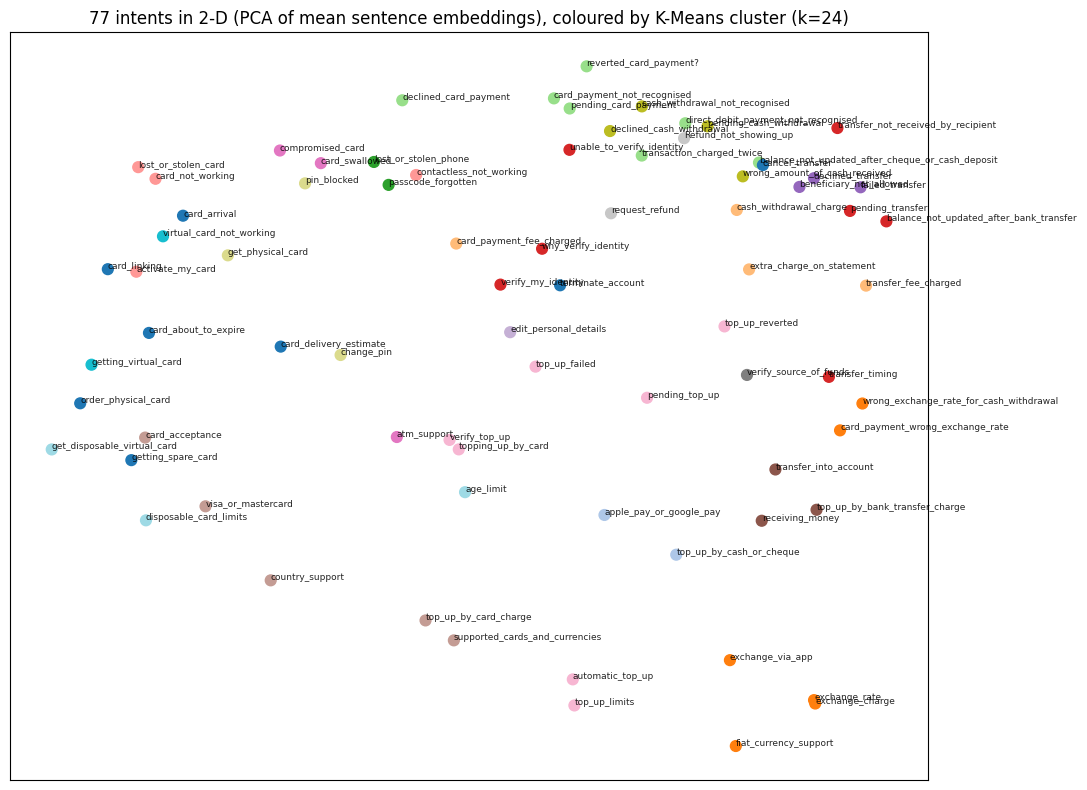

In [16]:
# Do the most-confused pairs from section 8 share a cluster?
top_pairs = pairs[:10]
same = [(n, a, b) for n, a, b in top_pairs if cluster_of[label2id[a]] == cluster_of[label2id[b]]]
print(f"{len(same)} of {len(top_pairs)} most-confused intent pairs fall in the same K-Means cluster")
for n, a, b in top_pairs:
    flag = "same cluster" if cluster_of[label2id[a]] == cluster_of[label2id[b]] else "different"
    print(f"  {n:>2} x  {a}  ->  {b}   [{flag}]")

# 2-D PCA map of the 77 intents, coloured by cluster
xy = PCA(n_components=2, random_state=SEED).fit_transform(centroids)
fig, ax = plt.subplots(figsize=(11, 8))
ax.scatter(xy[:, 0], xy[:, 1], c=cluster_of, cmap="tab20", s=60)
for i, label in id2label.items():
    ax.annotate(label, xy[i], fontsize=6.5, alpha=0.85)
ax.set_title(f"77 intents in 2-D (PCA of mean sentence embeddings), coloured by K-Means cluster (k={best_k})")
ax.set_xticks([]); ax.set_yticks([])
plt.tight_layout(); plt.show()

**Reading the result:** if most confused pairs share a cluster, the model's errors come from genuinely overlapping intents rather than random mistakes. That supports two practical fixes: a two-stage router (first the cluster, then the exact intent), or merging intents that the business handles the same way.

## 14. Experiment tracking with MLflow

Every model run in this notebook is logged to **MLflow** with its parameters and test metrics, so runs can be compared and reproduced.

In [18]:
!pip install -q mlflow
import mlflow

mlflow.set_tracking_uri("sqlite:///mlflow.db")
mlflow.set_experiment("banking77-intent-classification")

with mlflow.start_run(run_name="tfidf-logreg-baseline"):
    mlflow.log_params({"model": "TF-IDF + LogisticRegression", "ngram_range": "1-2", "min_df": 2, "C": 10,
                       "n_features": n_features_all})
    mlflow.log_metrics({"test_accuracy": baseline_acc, "test_macro_f1": baseline_f1})

for _, row in feature_selection_table.iloc[1:].iterrows():
    with mlflow.start_run(run_name=f"tfidf-logreg-chi2-k{int(row['features kept'])}"):
        mlflow.log_params({"model": "TF-IDF + chi2 + LogisticRegression", "k_features": int(row["features kept"]), "C": 10})
        mlflow.log_metrics({"test_accuracy": row["test accuracy"], "test_macro_f1": row["test macro-F1"]})

with mlflow.start_run(run_name="distilbert-finetuned"):
    mlflow.log_params({"model": MODEL_NAME, "epochs": args.num_train_epochs, "learning_rate": args.learning_rate,
                       "batch_size": args.per_device_train_batch_size, "weight_decay": args.weight_decay,
                       "max_length": 64, "best_epoch_metric": "macro_f1"})
    for _, row in val_hist.iterrows():
        step = int(round(row["epoch"]))
        mlflow.log_metric("val_macro_f1", row["eval_macro_f1"], step=step)
        mlflow.log_metric("val_loss", row["eval_loss"], step=step)
    mlflow.log_metrics({"test_accuracy": bert_acc, "test_macro_f1": bert_f1,
                        "auto_routed_pct_at_0.9": chosen["auto-routed (%)"],
                        "accuracy_on_auto_routed_pct_at_0.9": chosen["accuracy on auto-routed (%)"]})

runs = mlflow.search_runs(experiment_names=["banking77-intent-classification"])
cols = ["tags.mlflow.runName", "metrics.test_accuracy", "metrics.test_macro_f1"]
print(runs[cols].sort_values("metrics.test_macro_f1", ascending=False).round(4).to_string(index=False))

2026/10/21 03:50:08 INFO mlflow.store.db.utils: Creating initial MLflow database tables...
2026/10/21 03:50:08 INFO mlflow.store.db.utils: Updating database tables
2026/10/21 03:50:12 INFO mlflow.tracking.fluent: Experiment with name 'banking77-intent-classification' does not exist. Creating a new experiment.


    tags.mlflow.runName  metrics.test_accuracy  metrics.test_macro_f1
   distilbert-finetuned                 0.9169                 0.9168
  tfidf-logreg-baseline                 0.8851                 0.8854
tfidf-logreg-chi2-k5000                 0.8831                 0.8833
tfidf-logreg-chi2-k2500                 0.8792                 0.8796
tfidf-logreg-chi2-k1000                 0.8406                 0.8423


## Summary

| | Test accuracy | Test macro-F1 |
|---|---|---|
| TF-IDF + Logistic Regression | *see section 7* | *see section 7* |
| DistilBERT (fine-tuned) | *see section 7* | *see section 7* |

**Takeaways:** fine-tuning a pretrained Transformer captures the *meaning* of a message rather than just its words, which matters when 77 intents differ by small details. The classical baseline is still strong, cheap and explainable, which is why it is the benchmark to beat. The remaining errors are mostly between near-duplicate intents.